In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [26]:
df = pd.read_excel("Cleaned_DataV4.xlsx")

In [ ]:
df.head()

In [28]:
df_clean = df.copy()

In [29]:
print("Shape:", df_clean.shape)
print("Duplicate:", df_clean.duplicated().sum())
print("\nMissing:")
print(df_clean.isna().sum().sort_values(ascending=False))

Shape: (36722, 16)
Duplicate: 3

Missing:
Ghi chú              21923
Giới tính                0
Ngày nhập học            0
Ngày sinh                0
HKTT_Huyện               0
Khu vực                  0
Tên tỉnh THPT            0
HKTT_Tỉnh                0
Trường tốt nghiệp        0
Khóa học                 0
Loại đào tạo             0
Bậc đào tạo              0
Ngành                    0
Nghề                     0
Niên khóa                0
Trạng thái               0
dtype: int64


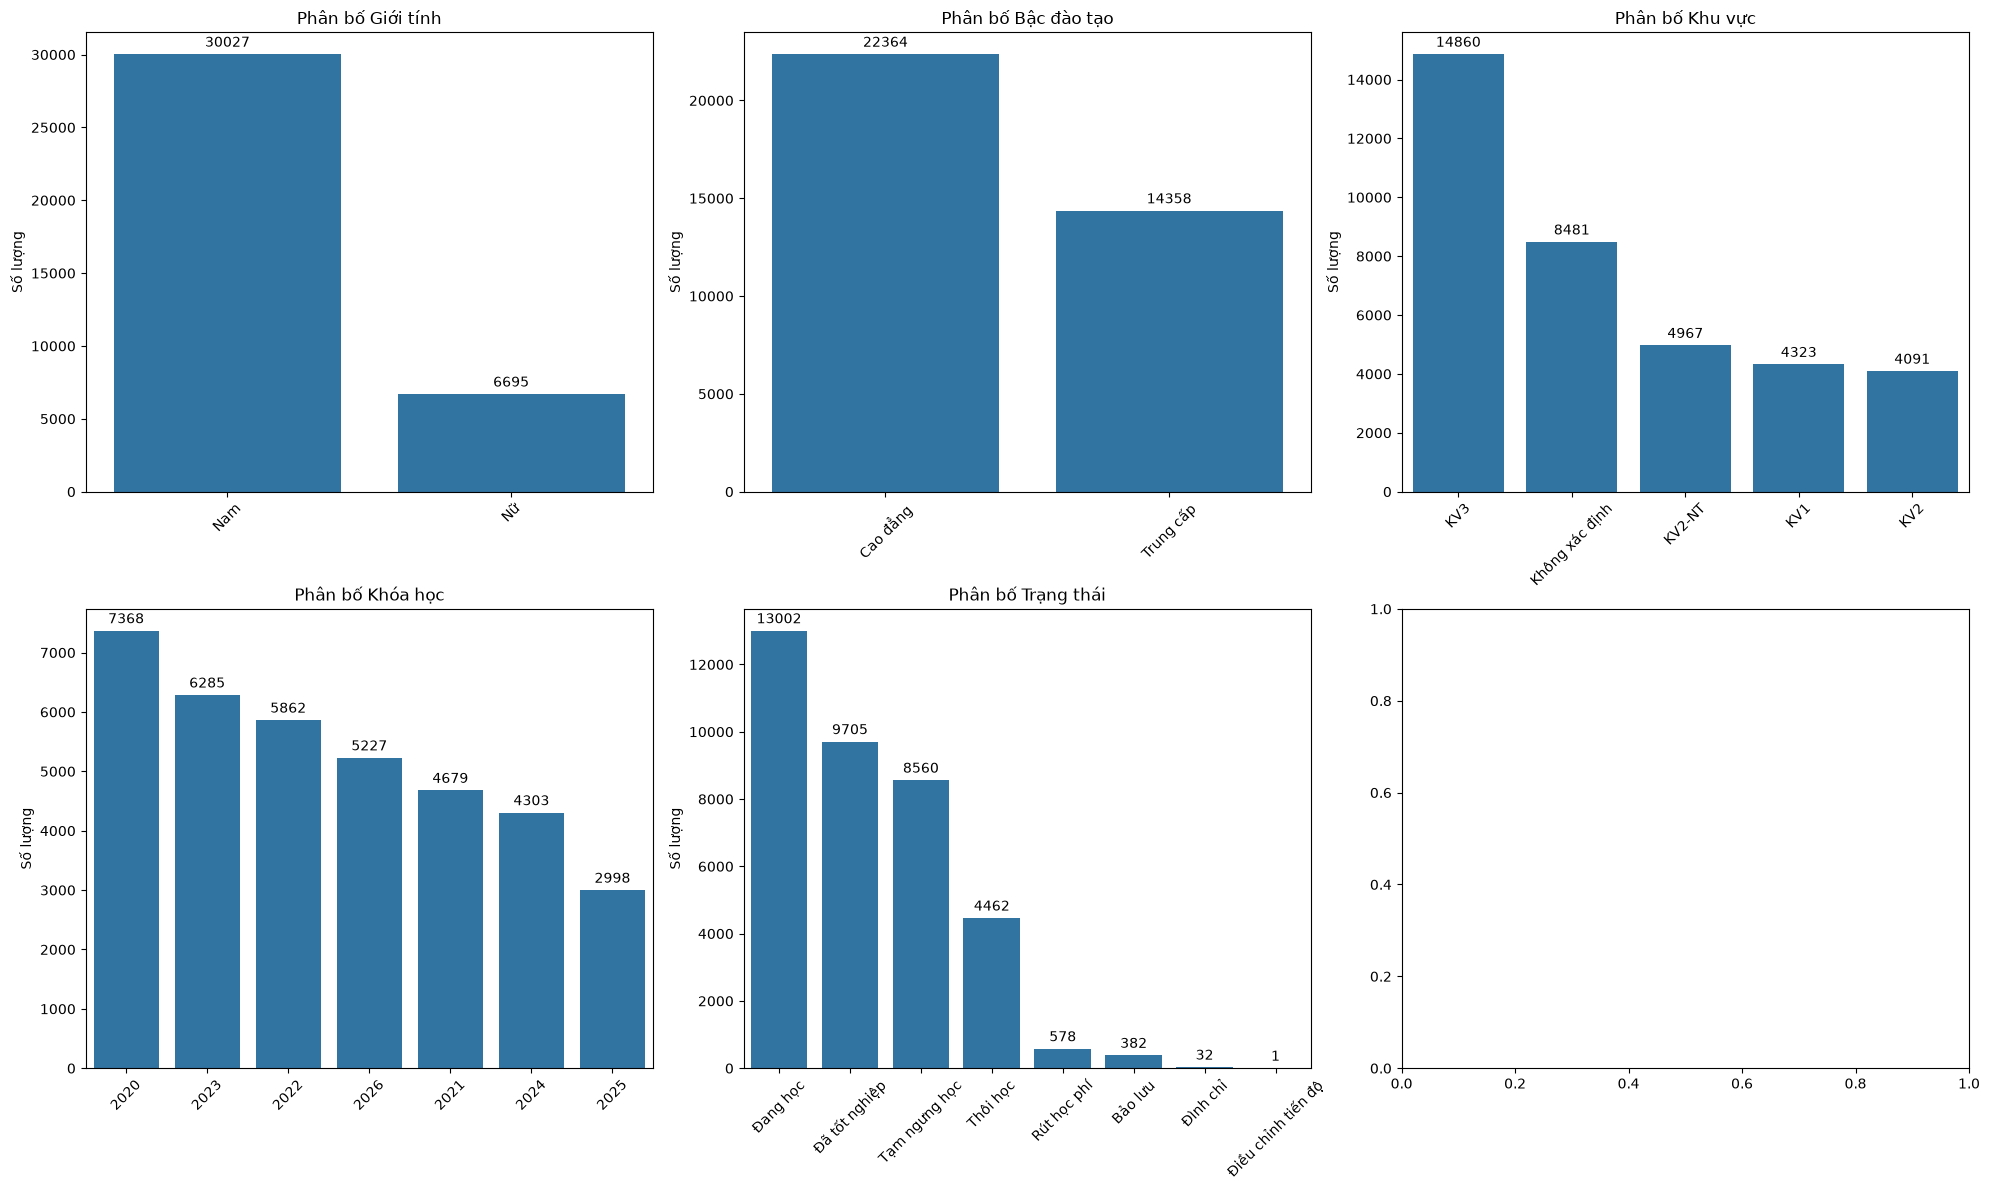

In [30]:
cols = [
    "Giới tính",
    "Bậc đào tạo",
    "Khu vực",
    "Khóa học",
    "Trạng thái"
]

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.countplot(
        data=df_clean,
        x=col,
        ax=ax,
        order=df_clean[col].value_counts().index
    )

    ax.set_title(f"Phân bố {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Số lượng")
    ax.tick_params(axis="x", rotation=45)

    # Hiện số lượng trên mỗi bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [31]:
print(df_clean["Niên khóa"].value_counts(dropna=False).head(100))

Niên khóa
2020 - 2023    5837
2026 - 2029    4985
2021 - 2024    4556
2022 - 2025    4357
2023 - 2026    3299
2023 - 2025    2913
2024 - 2027    2782
2025 - 2028    2182
2024 - 2026    1521
2022 - 2024    1505
2020 - 2022    1496
2025 - 2027     816
2026 - 2028     242
2021 - 2023     123
2023 - 2024      73
2020 - 2021      35
Name: count, dtype: int64


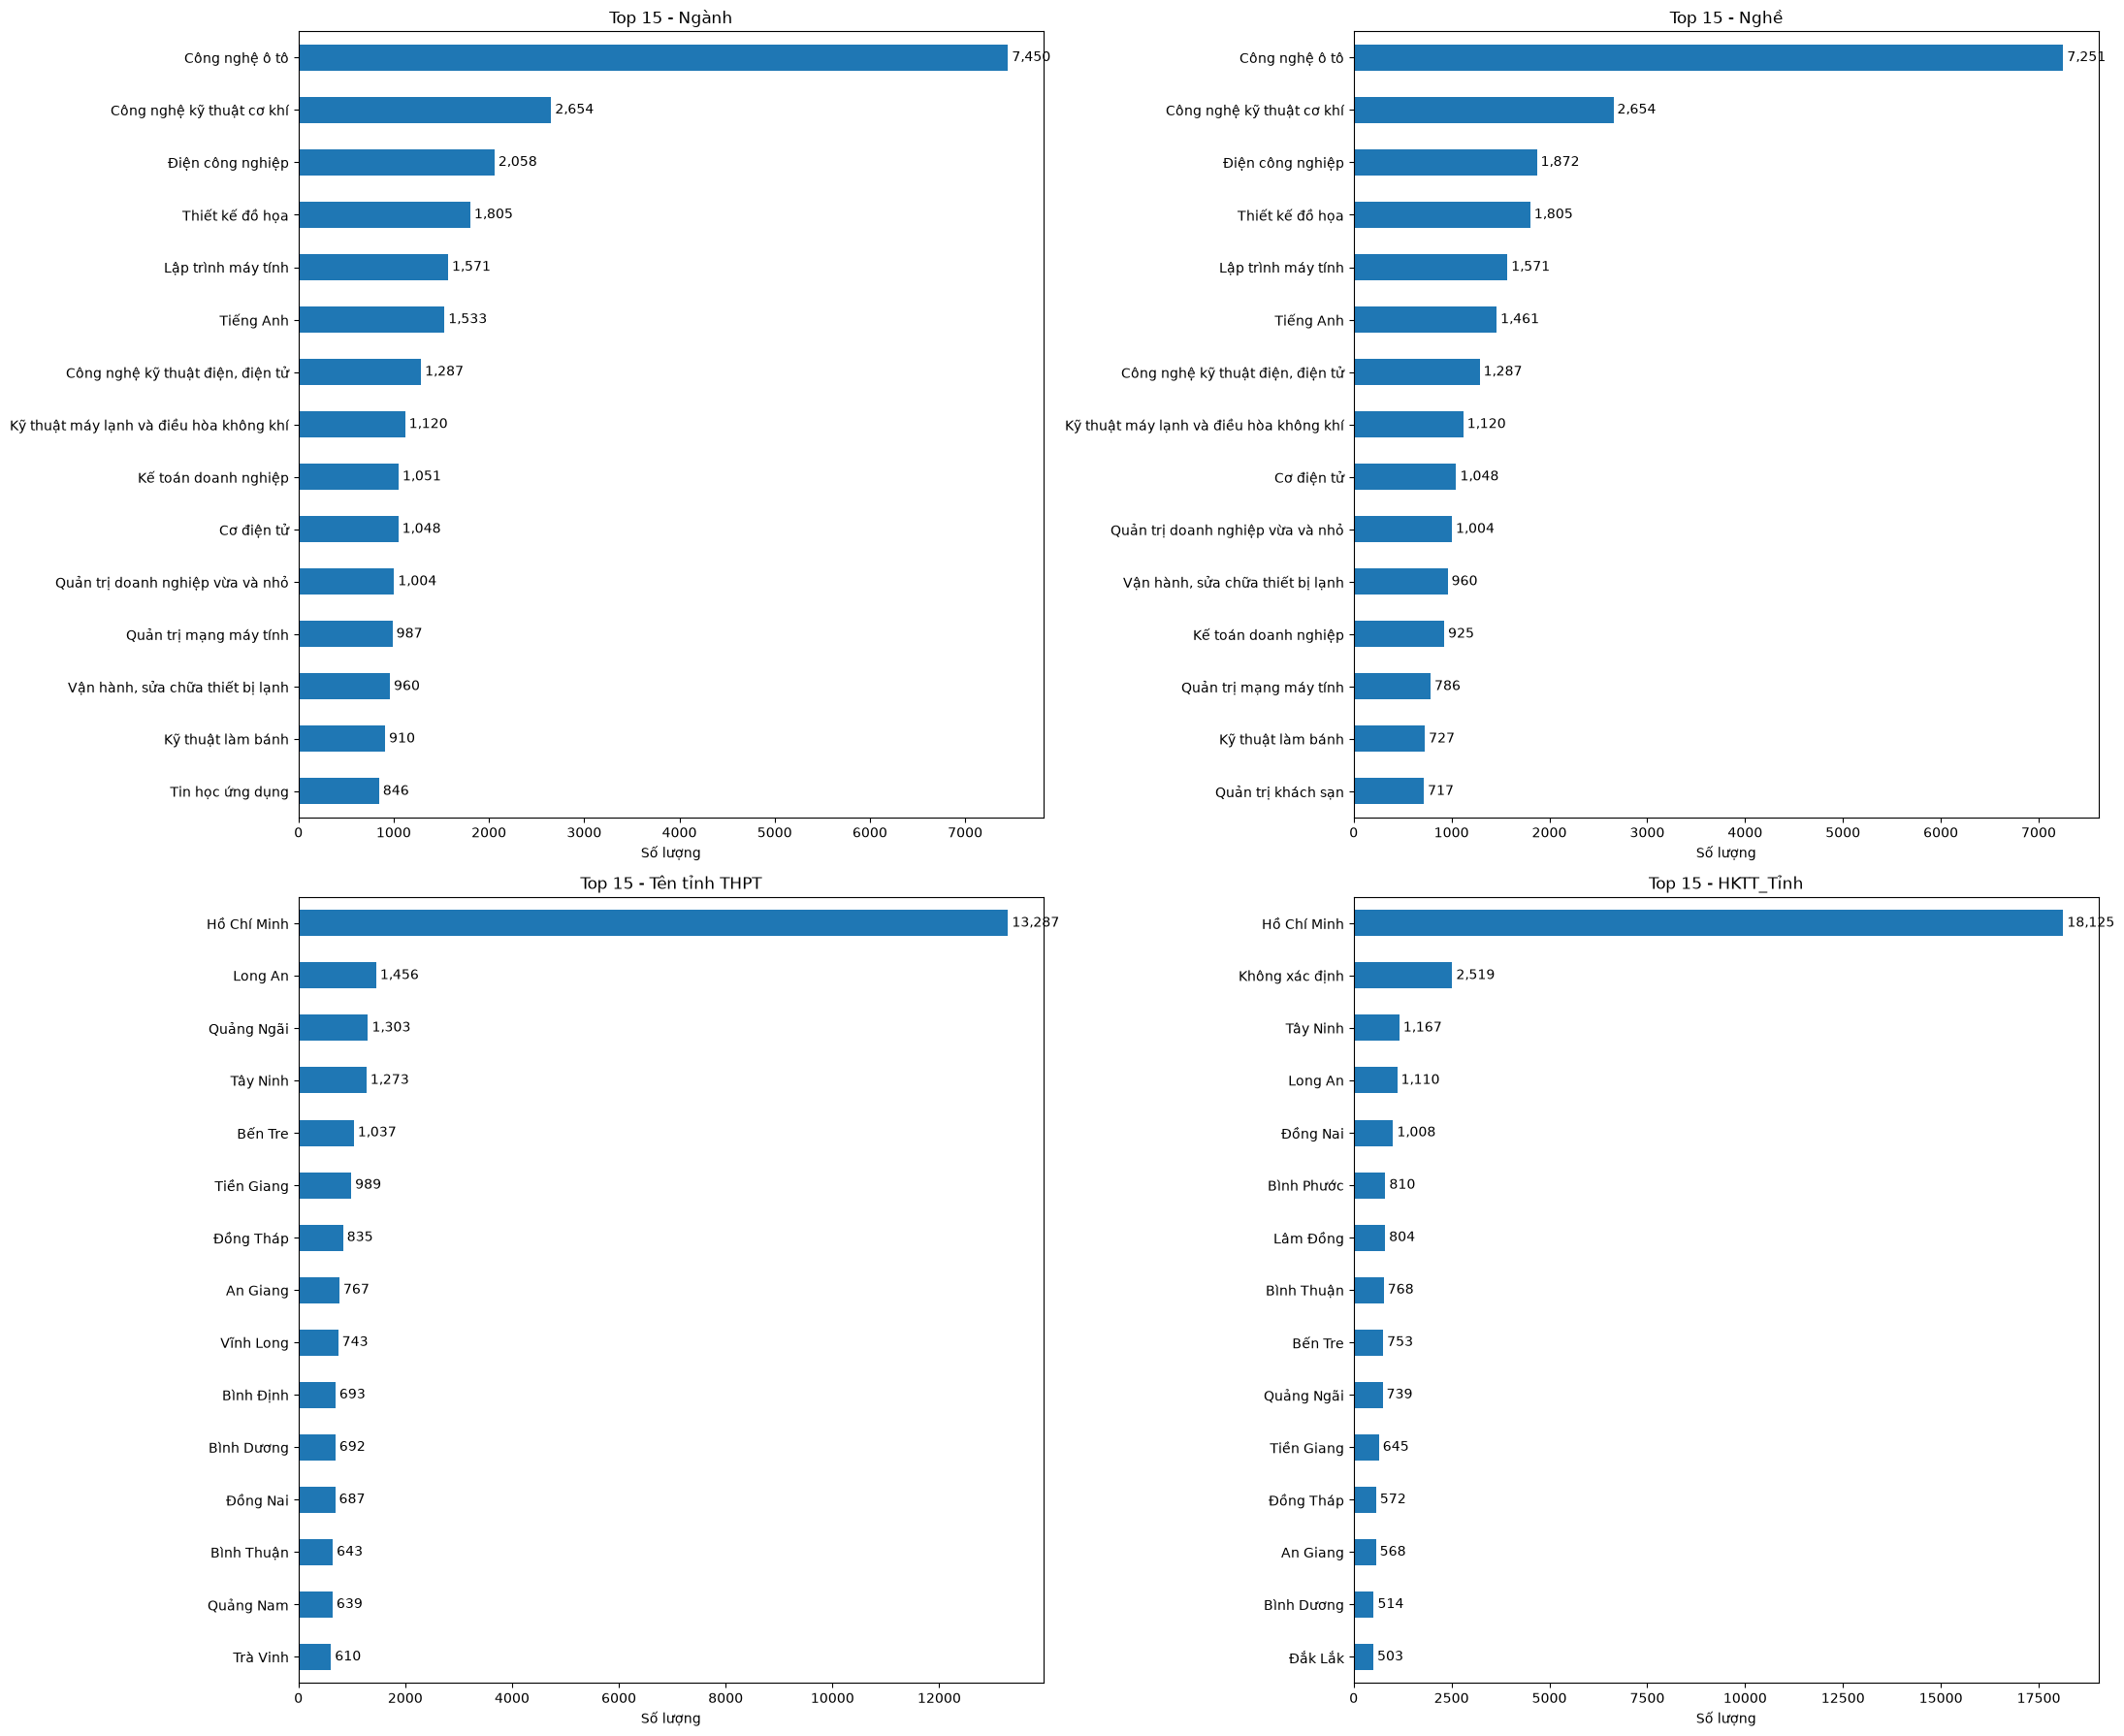

In [32]:
configs = {
    "Ngành": 15,
    "Nghề": 15,
    "Tên tỉnh THPT": 15,
    "HKTT_Tỉnh": 15
}

fig, axes = plt.subplots(2, 2, figsize=(22, 18))
axes = axes.flatten()

for ax, (col, top_n) in zip(axes, configs.items()):

    counts = (
        df_clean[col]
        .value_counts()
        .head(top_n)
        .sort_values()
    )

    counts.plot(
        kind="barh",
        ax=ax
    )

    ax.set_title(f"Top {top_n} - {col}")
    ax.set_xlabel("Số lượng")
    ax.set_ylabel("")

    # Hiện số lượng ở cuối bar
    for i, value in enumerate(counts):
        ax.text(
            value,
            i,
            f" {value:,}",
            va="center"
        )

plt.tight_layout()
plt.show()

In [34]:
censored = df_clean[
    df_clean["Trường tốt nghiệp"]
    == "censored"
]

print("Số lượng:", len(censored))

print("\nBậc đào tạo:")
print(censored["Bậc đào tạo"].value_counts())

print("\nLoại đào tạo:")
print(censored["Loại đào tạo"].value_counts())

print("\nKhóa học:")
print(censored["Khóa học"].value_counts().sort_index())

Số lượng: 4755

Bậc đào tạo:
Bậc đào tạo
Cao đẳng     4752
Trung cấp       3
Name: count, dtype: int64

Loại đào tạo:
Loại đào tạo
Liên thông           3875
Liên thông B          800
Chính quy 2.5 năm      76
Chính quy 3 năm         3
Liên kết Quốc tế        1
Name: count, dtype: int64

Khóa học:
Khóa học
2020      18
2021      27
2022    1197
2023    1543
2024    1193
2025     707
2026      70
Name: count, dtype: int64
